# 15 - Curves and 2-D maps with grid solvers

Three short studies that share one idea: an empirical lookup is a **curve or a surface**, and it
becomes useful when it drives a grid solver.

* **A. Inverter volt-var and volt-watt control.** A custom `ModelComponent` reads the feeder voltage from
  OpenDSS and sets the PV inverter's reactive and active power through two `Curve1D` functions. We
  compare *no control*, *volt-var* and *volt-watt* on the same feeder.
* **B. A heat-pump COP map.** A `Surface2D(T_source, T_sink)` gives the COP. A temperature series turns
  into an electric load on a PyPSA network, and we read the line loading and the slack generator.
* **C. Dynamic line rating and a self-contained load-flow solver.** A `Surface2D(T_ambient, wind)` gives a
  per-line ampacity. A Newton-Raphson AC power flow, written in NumPy and as an Octave function with
  MATPOWER-style arrays, is cross-checked against pandapower.

**Optional dependencies.** Section A needs `opendssdirect`. Section B needs `pypsa`. Section C always runs
its NumPy solver and pandapower check (pandapower is needed for the comparison). The Octave function runs
only if `oct2py` and a working GNU Octave are present. Otherwise that cell says so and skips.

All parameters are illustrative. Conductors, curves and ratings must come from the equipment standard and
the utility's grid code before you use the numbers.

In [1]:
import math
import tempfile
import warnings
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
import pandas as pd

from energysim import world
from energysim.models.common.base_component import ModelComponent
from energysim.models.common.curve import Curve1D, Surface2D

try:
    import opendssdirect  # noqa: F401
    HAS_DSS = True
except ImportError:
    HAS_DSS = False

try:
    import pypsa  # noqa: F401
    HAS_PYPSA = True
except ImportError:
    HAS_PYPSA = False

try:
    import pandapower  # noqa: F401
    HAS_PP = True
except ImportError:
    HAS_PP = False

def _octave_available():
    """oct2py must import AND a GNU Octave session must start."""
    try:
        from oct2py import Oct2Py
    except ImportError:
        return False
    try:
        oc = Oct2Py()
        oc.exit()
        return True
    except Exception:
        return False


HAS_OCT = _octave_available()

WORK_DIR = Path(tempfile.mkdtemp(prefix="energysim_nb15_"))
print(f"OpenDSS: {HAS_DSS}  PyPSA: {HAS_PYPSA}  pandapower: {HAS_PP}  oct2py: {HAS_OCT}")
print(f"Scratch folder: {WORK_DIR}")

octave not found, please see README
OpenDSS: True  PyPSA: False  pandapower: True  oct2py: False
Scratch folder: C:\Users\digvi\AppData\Local\Temp\energysim_nb15_2n98fmhp


## A. Inverter volt-var and volt-watt control in closed loop with an OpenDSS feeder

### The control curves

Two curves describe what a grid-following inverter does at its point of connection:

* **Volt-var.** Below about 0.98 pu the inverter injects reactive power, and above about 1.02 pu it absorbs
  it. The output is a fraction of the reactive capacity that is left after the active power is served:
  `Q = f_var(V) * Q_available`, with `Q_available = sqrt(S_rated^2 - P^2)`.
* **Volt-watt.** Above 1.03 pu the inverter curtails its active power linearly, down to 20 % at 1.08 pu:
  `P = f_watt(V) * P_available`.

`Curve1D` clamps outside its range, so the curves are safe at any voltage. The loop closes through the
feeder: the inverter sets P and Q, the feeder solves, and the new voltage returns to the inverter one
macro step later (energysim's Jacobi exchange).

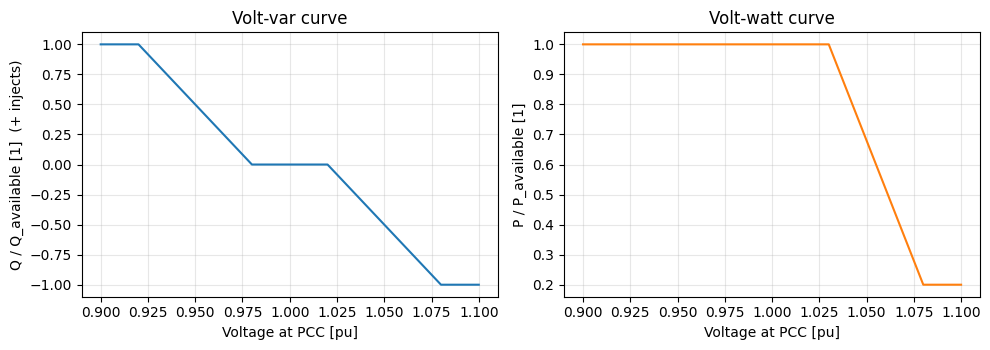

C:\Users\digvi\AppData\Local\Temp\ipykernel_27492\2047606244.py:89: UserWarning: Algebraic loop detected involving simulators: ['feeder', 'inv']. Using Jacobi coupling (one-step delay) for these cyclic dependencies. Reduce t_macro or merge the coupled components to limit the delay error.
  sim.add_connections({
C:\Users\digvi\AppData\Local\Temp\ipykernel_27492\2047606244.py:89: UserWarning: Algebraic loop detected involving simulators: ['feeder', 'inv']. Using Jacobi coupling (one-step delay) for these cyclic dependencies. Reduce t_macro or merge the coupled components to limit the delay error.
  sim.add_connections({
C:\Users\digvi\AppData\Local\Temp\ipykernel_27492\2047606244.py:89: UserWarning: Algebraic loop detected involving simulators: ['feeder', 'inv']. Using Jacobi coupling (one-step delay) for these cyclic dependencies. Reduce t_macro or merge the coupled components to limit the delay error.
  sim.add_connections({


,max V at PCC [pu],time of max [h],mean losses [kW]
none,1.0218,12.1667,8.8866
volt-var,1.0215,12.1667,8.8900
volt-watt,1.0218,12.1667,8.8866


In [2]:
VAR_CURVE = Curve1D(x=[0.92, 0.98, 1.02, 1.08], y=[1.0, 0.0, 0.0, -1.0],
                    min_val=-1.0, max_val=1.0, name="volt-var (fraction of Q available)")
WATT_CURVE = Curve1D(x=[1.00, 1.03, 1.08], y=[1.0, 1.0, 0.2],
                     min_val=0.0, max_val=1.0, name="volt-watt (fraction of P available)")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
v_axis = np.linspace(0.90, 1.10, 201)
axes[0].plot(v_axis, [VAR_CURVE(v) for v in v_axis], color="tab:blue")
axes[0].set_xlabel("Voltage at PCC [pu]")
axes[0].set_ylabel("Q / Q_available [1]  (+ injects)")
axes[0].set_title("Volt-var curve")
axes[0].grid(alpha=0.3)
axes[1].plot(v_axis, [WATT_CURVE(v) for v in v_axis], color="tab:orange")
axes[1].set_xlabel("Voltage at PCC [pu]")
axes[1].set_ylabel("P / P_available [1]")
axes[1].set_title("Volt-watt curve")
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()


class PVInverterControl(ModelComponent):
    """Grid-following PV inverter with optional volt-var or volt-watt control.

    Inputs: ``V_pu`` (voltage at the point of connection) and ``P_avail_kW`` (PV available power).
    Outputs: ``P_kW`` and ``Q_kvar`` for the OpenDSS generator (positive = injection).
    """

    units = {"V_pu": "pu", "P_avail_kW": "kW", "P_kW": "kW", "Q_kvar": "kvar", "S_rated_kVA": "kVA"}

    def __init__(self, name="inverter", mode="none", s_rated_kva=1500.0, step_size=300.0, **kwargs):
        super().__init__(name=name, step_size=step_size, **kwargs)
        if mode not in ("none", "volt-var", "volt-watt"):
            raise ValueError(f"unknown mode {mode!r}")
        self.mode = mode
        self.s_rated = float(s_rated_kva)
        self.register_variables(inputs=["V_pu", "P_avail_kW"],
                                outputs=["P_kW", "Q_kvar"],
                                defaults={"V_pu": 1.0, "P_avail_kW": 0.0})
        self.register_parameters("s_rated")

    def step_model(self, dt: float, time: float) -> None:
        v = float(self._inputs_val.get("V_pu", 1.0))
        p_av = max(0.0, float(self._inputs_val.get("P_avail_kW", 0.0)))
        p = p_av
        if self.mode == "volt-watt":
            p = p_av * float(WATT_CURVE(v))
        q_avail = math.sqrt(max(0.0, self.s_rated ** 2 - p ** 2))
        q = 0.0
        if self.mode == "volt-var":
            q = float(VAR_CURVE(v)) * q_avail
        self._outputs_val["P_kW"] = p
        self._outputs_val["Q_kvar"] = q


PV_FEEDER_DSS = """Clear
New Circuit.pvfeeder basekv=11 pu=1.0 phases=3 bus1=src
New Line.l1 bus1=src bus2=n1 phases=3 r1=1.0 x1=0.5 length=1.5 units=km
New Line.l2 bus1=n1 bus2=n2 phases=3 r1=1.0 x1=0.5 length=1.5 units=km
New Load.ld1 bus1=n1 phases=3 kv=11 kw=300 kvar=0 model=1
New Load.ld2 bus1=n2 phases=3 kv=11 kw=150 kvar=0 model=1
New Generator.inv bus1=n2 phases=3 kv=11 kw=0 kvar=0 model=1
Set voltagebases=[11]
Calcvoltagebases
Solve
"""
PV_FEEDER_FILE = WORK_DIR / "pv_feeder.dss"
PV_FEEDER_FILE.write_text(PV_FEEDER_DSS, encoding="utf-8")


def pv_available_kw(t):
    """PV available power [kW]: 1.2 MW peak at 12:00, zero before 06:00 and after 18:00."""
    hr = (t / 3600.0) % 24.0
    if 6.0 <= hr <= 18.0:
        return 1200.0 * math.sin(math.pi * (hr - 6.0) / 12.0)
    return 0.0


def run_pv_feeder(mode, t_start=6 * 3600.0, t_end=18 * 3600.0, step_s=300.0):
    """Closed-loop run of the PV feeder with the given inverter mode."""
    sim = world(start_time=t_start, stop_time=t_end, t_macro=step_s, power_unit="kW")
    sim.add_signal("irr", pv_available_kw, step_size=step_s, units={"y": "kW"})
    sim.add_model("inv", PVInverterControl(name="inv", mode=mode, s_rated_kva=1500.0, step_size=step_s),
                  step_size=step_s, outputs=["P_kW", "Q_kvar"])
    sim.add_opendss("feeder", model=str(PV_FEEDER_FILE), inputs=["Generator.inv.kW", "Generator.inv.kvar"],
                    outputs=["Bus.n2.vm_pu", "Bus.n1.vm_pu", "Circuit.losses_kw"], step_size=step_s,
                    power_unit="kW",
                    units={"Generator.inv.kW": "kW", "Generator.inv.kvar": "kvar"})
    sim.add_connections({
        "feeder.Bus.n2.vm_pu": "inv.V_pu",
        "irr.y": "inv.P_avail_kW",
        "inv.P_kW": "feeder.Generator.inv.kW",
        "inv.Q_kvar": "feeder.Generator.inv.kvar",
    })
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", UserWarning)
        return sim.simulate(pbar=False).to_frame()


if HAS_DSS:
    runs_a = {}
    for mode in ("none", "volt-var", "volt-watt"):
        runs_a[mode] = run_pv_feeder(mode)
    summary_a = pd.DataFrame({
        mode: {
            "max V at PCC [pu]": df["feeder.Bus.n2.vm_pu"].max(),
            "time of max [h]": df.index[df["feeder.Bus.n2.vm_pu"].to_numpy().argmax()] / 3600.0,
            "mean losses [kW]": df["feeder.Circuit.losses_kw"].mean(),
        } for mode, df in runs_a.items()
    }).T.round(4)
    display(summary_a)
else:
    runs_a = {}
    print("SKIP section A (opendssdirect not installed).")

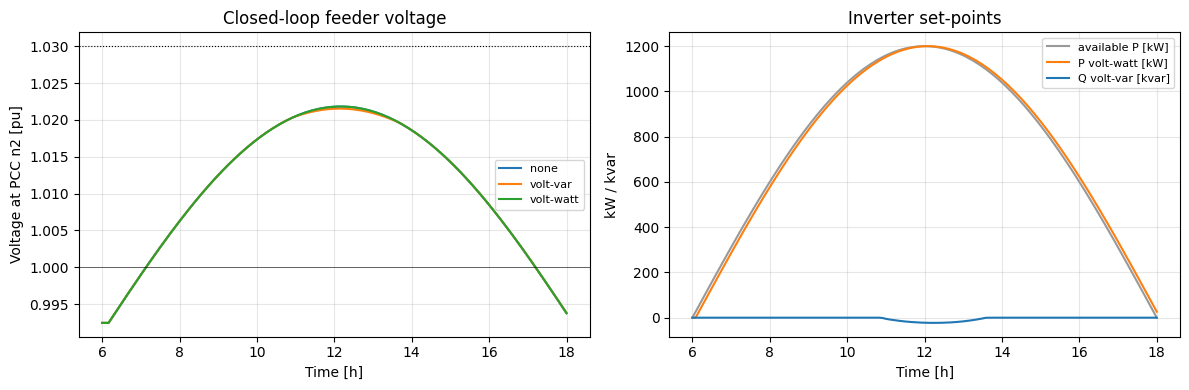

Volt-var absorbs reactive power when the voltage is high, which lowers the peak. Volt-watt cuts the active power instead, which lowers the peak more but gives up energy. Check which the grid code prescribes before choosing one.


In [3]:
if HAS_DSS:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for mode, df in runs_a.items():
        t_h = df.index.to_numpy() / 3600.0
        axes[0].plot(t_h, df["feeder.Bus.n2.vm_pu"], label=mode)
    axes[0].axhline(1.03, color="k", ls=":", lw=0.8)
    axes[0].axhline(1.0, color="k", ls="-", lw=0.4)
    axes[0].set_xlabel("Time [h]")
    axes[0].set_ylabel("Voltage at PCC n2 [pu]")
    axes[0].set_title("Closed-loop feeder voltage")
    axes[0].legend(fontsize=8)
    axes[0].grid(alpha=0.3)
    df_vv = runs_a["volt-var"]
    t_h = df_vv.index.to_numpy() / 3600.0
    axes[1].plot(t_h, [pv_available_kw(t) for t in df_vv.index.to_numpy()],
                 color="0.6", label="available P [kW]")
    axes[1].plot(t_h, runs_a["volt-watt"]["inv.P_kW"], color="tab:orange", label="P volt-watt [kW]")
    axes[1].plot(t_h, runs_a["volt-var"]["inv.Q_kvar"], color="tab:blue", label="Q volt-var [kvar]")
    axes[1].set_xlabel("Time [h]")
    axes[1].set_ylabel("kW / kvar")
    axes[1].set_title("Inverter set-points")
    axes[1].legend(fontsize=8)
    axes[1].grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
    print("Volt-var absorbs reactive power when the voltage is high, which lowers the peak. Volt-watt cuts the "
          "active power instead, which lowers the peak more but gives up energy. Check which the grid code "
          "prescribes before choosing one.")

## B. Heat-pump COP surface driving a PyPSA load

The COP of a heat pump depends on the source temperature (air, ground or water) and on the sink
temperature. A simple, widely used form is a fraction of the Carnot COP. `Surface2D` interpolates the
COP bilinearly over a grid and clamps outside it.

The cell below builds the grid from the Carnot formula. A ModelComponent (`HeatPumpFromCOPMap`) reads
the source temperature and the required heat, then sets the electric power. PyPSA then solves the
power flow for that load on a 20 kV three-bus network with a slack generator.

COP at (0 degC source, 50 degC sink): 2.908
COP at (-10 degC source, 50 degC sink): 2.424


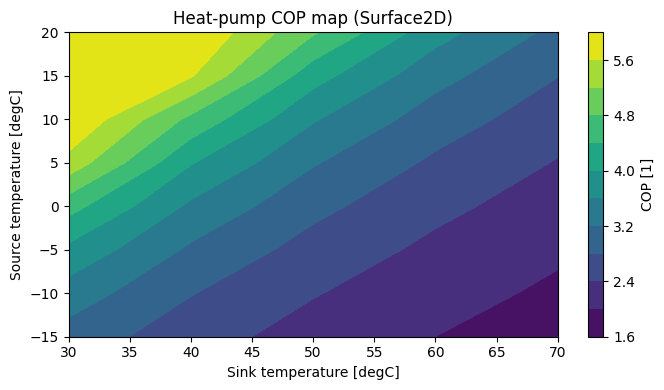

SKIP section B (pypsa not installed).


In [4]:
T_SRC_GRID = np.array([-15.0, -10.0, -5.0, 0.0, 5.0, 10.0, 15.0, 20.0])   # degC, source
T_SNK_GRID = np.array([30.0, 40.0, 50.0, 60.0, 70.0])                     # degC, sink
CARNOT_FRACTION = 0.45
COP_Z = np.zeros((T_SRC_GRID.size, T_SNK_GRID.size))
for i, t_src in enumerate(T_SRC_GRID):
    for j, t_snk in enumerate(T_SNK_GRID):
        lift = max(t_snk - t_src, 5.0)
        COP_Z[i, j] = np.clip(CARNOT_FRACTION * (t_snk + 273.15) / (lift), 1.5, 6.0)
COP_MAP = Surface2D(T_SRC_GRID, T_SNK_GRID, COP_Z, name="COP(T_source, T_sink)")

print("COP at (0 degC source, 50 degC sink):", round(float(COP_MAP(0.0, 50.0)), 3))
print("COP at (-10 degC source, 50 degC sink):", round(float(COP_MAP(-10.0, 50.0)), 3))

fig, ax = plt.subplots(figsize=(7, 4))
cs = ax.contourf(T_SNK_GRID, T_SRC_GRID, COP_Z, levels=12, cmap="viridis")
fig.colorbar(cs, ax=ax, label="COP [1]")
ax.set_xlabel("Sink temperature [degC]")
ax.set_ylabel("Source temperature [degC]")
ax.set_title("Heat-pump COP map (Surface2D)")
plt.tight_layout()
plt.show()


class HeatPumpFromCOPMap(ModelComponent):
    """Heat pump whose COP comes from a Surface2D: P_elec = Q_heat / COP(T_source, T_sink)."""

    units = {"T_source": "degC", "T_sink": "degC", "Q_heat_MW": "MW", "COP": "1", "P_elec_MW": "MW"}

    def __init__(self, name="hp_map", cop_surface=COP_MAP, q_max_mw=2.5, step_size=900.0, **kwargs):
        super().__init__(name=name, step_size=step_size, **kwargs)
        self.surface = cop_surface
        self.q_max = float(q_max_mw)
        self.register_variables(inputs=["T_source", "T_sink", "Q_heat_MW"],
                                outputs=["COP", "P_elec_MW"],
                                defaults={"T_source": 0.0, "T_sink": 45.0, "Q_heat_MW": 0.0})

    def step_model(self, dt: float, time: float) -> None:
        t_src = float(self._inputs_val.get("T_source", 0.0))
        t_snk = float(self._inputs_val.get("T_sink", 45.0))
        q = min(self.q_max, max(0.0, float(self._inputs_val.get("Q_heat_MW", 0.0))))
        cop = float(self.surface(t_src, t_snk))
        self._outputs_val["COP"] = cop
        self._outputs_val["P_elec_MW"] = q / cop


def air_temp_c(t):
    """Winter air temperature [degC]: -7 at 03:00, -1 at 15:00."""
    return -4.0 + 3.0 * math.cos(2.0 * math.pi * (t - 15.0 * 3600.0) / 86400.0)


def heat_demand_mw(t):
    """Space-heating demand [MW] for a 2.5 MW plant: scales with the cold, with a floor at 25 %."""
    return 2.5 * max(0.25, (18.0 - air_temp_c(t)) / 25.0)


def build_pypsa_grid():
    """A 20 kV three-bus feeder: slack at b0, base load at b1, heat-pump load at b2."""
    n = pypsa.Network()
    for b in ("b0", "b1", "b2"):
        n.add("Bus", b, v_nom=20.0)
    n.add("Line", "l01", bus0="b0", bus1="b1", x=0.40, r=0.20, s_nom=3.0)
    n.add("Line", "l12", bus0="b1", bus1="b2", x=0.40, r=0.20, s_nom=2.0)
    n.add("Generator", "g0", bus="b0", control="Slack", p_set=0.0)
    n.add("Load", "base", bus="b1", p_set=1.2, q_set=0.2)
    n.add("Load", "hp_load", bus="b2", p_set=0.0, q_set=0.0)
    return n


if HAS_PYPSA:
    import pypsa  # noqa: E402  (needed by build_pypsa_grid)

    sim_b = world(start_time=0, stop_time=86400, t_macro=900, power_unit="MW")
    sim_b.add_signal("t_air", air_temp_c, step_size=900, units={"y": "degC"})
    sim_b.add_signal("t_sink", 45.0, step_size=900, units={"y": "degC"})
    sim_b.add_signal("q_heat", heat_demand_mw, step_size=900, units={"y": "MW"})
    sim_b.add_model("hp_map", HeatPumpFromCOPMap(name="hp_map", q_max_mw=2.5), step_size=900,
                    outputs=["COP", "P_elec_MW"])
    sim_b.add_pypsa("dist_grid", model=build_pypsa_grid(), inputs=["hp_load.P"],
                    outputs=["g0.P", "l01.loading_percent", "l12.loading_percent", "b2.V"],
                    step_size=900, power_unit="MW")
    sim_b.add_connections({
        "t_air.y": "hp_map.T_source",
        "t_sink.y": "hp_map.T_sink",
        "q_heat.y": "hp_map.Q_heat_MW",
        "hp_map.P_elec_MW": "dist_grid.hp_load.P",
    })
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", UserWarning)
        res_b = sim_b.simulate(pbar=False)
    df_b = res_b.to_frame()
    t_h = df_b.index.to_numpy() / 3600.0
    fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
    axes[0].plot(t_h, df_b["hp_map.COP"], color="tab:green", label="COP from map")
    axes[0].set_ylabel("COP [1]")
    axes[0].legend(fontsize=8)
    axes[0].grid(alpha=0.3)
    axes[1].plot(t_h, df_b["dist_grid.l01.loading_percent"], label="line l01 (slack side) [%]")
    axes[1].plot(t_h, df_b["dist_grid.l12.loading_percent"], label="line l12 (heat-pump branch) [%]")
    axes[1].plot(t_h, df_b["dist_grid.g0.P"] * 10.0, "k--", label="slack generator P x 10 [MW]")
    axes[1].set_ylabel("Loading [%] / power")
    axes[1].set_xlabel("Time [h]")
    axes[1].legend(fontsize=8)
    axes[1].grid(alpha=0.3)
    fig.suptitle("Heat-pump load on a PyPSA network: COP map to line loading")
    plt.tight_layout()
    plt.show()
    print(f"Slack generator P: {df_b['dist_grid.g0.P'].min():.3f} .. {df_b['dist_grid.g0.P'].max():.3f} MW")
else:
    print("SKIP section B (pypsa not installed).")

## C. Dynamic line rating and a Newton-Raphson AC power flow

### Dynamic line rating (DLR)

A conductor's ampacity is set by how fast it sheds heat. Cold, windy air cools it, so the ampacity is
higher. A static rating assumes the worst case all year. A dynamic rating uses the weather.

A simplified steady-state heat balance (in the spirit of IEEE 738, but deliberately simplified) gives the
current `I` from the convective and radiative losses `q_c + q_r` and the AC resistance `R`:

$$I = \sqrt{\frac{q_c + q_r}{R_{ac}}}, \qquad q_c = h(v)\,\pi D\,(T_c - T_a), \qquad q_r = \varepsilon\sigma\pi D\,(T_c^4 - T_a^4)$$

with `h(v) = 3 + 6 sqrt(v)` W/(m2 K). The ampacity is tabulated over ambient temperature and effective
wind speed in a `Surface2D`. Each line has a *shelter* factor, which reduces the wind it sees.

The conductor here is a small illustrative one (D = 10 mm, R = 0.6 ohm/km). It is not a standard
conductor, so the absolute currents are only indicative.

In [5]:
C_DIAM_M = 0.010
C_RAC_OHM_PER_M = 6.0e-4
C_TC_C = 75.0
C_EMIS = 0.5
SIGMA = 5.67e-8

T_AMB_GRID = np.array([-10.0, 0.0, 10.0, 20.0, 30.0, 40.0])
V_WIND_GRID = np.array([0.0, 1.0, 2.0, 4.0, 8.0, 12.0])


def ampacity_a(t_amb_c, v_ms):
    """Simplified steady-state ampacity [A] of the illustrative conductor."""
    h = 3.0 + 6.0 * math.sqrt(max(v_ms, 0.0))
    q_c = h * math.pi * C_DIAM_M * (C_TC_C - t_amb_c)
    q_r = C_EMIS * SIGMA * ((C_TC_C + 273.15) ** 4 - (t_amb_c + 273.15) ** 4) * math.pi * C_DIAM_M
    return math.sqrt(max(q_c + q_r, 0.0) / C_RAC_OHM_PER_M)


AMPACITY_Z = np.array([[ampacity_a(ta, v) for v in V_WIND_GRID] for ta in T_AMB_GRID])
AMPACITY_MAP = Surface2D(T_AMB_GRID, V_WIND_GRID, AMPACITY_Z, name="ampacity [A](T_amb, wind)")
print("Ampacity [A] at -10 degC / 8 m/s:", round(float(AMPACITY_MAP(-10.0, 8.0)), 1),
      "  at 30 degC / calm:", round(float(AMPACITY_MAP(30.0, 0.0)), 1))

Ampacity [A] at -10 degC / 8 m/s: 321.8   at 30 degC / calm: 127.8


### The test network

Five buses at 20 kV, in a mesh, with a slack bus, a PV generator and three loads. Resistances and
reactances are per km, with a 1 km to 2 km spacing. Per-unit values use `S_base = 10 MVA`. We use the same
MATPOWER-style arrays for the NumPy solver, the Octave function and pandapower.

The branch ratings come from the DLR: each line's wind is its own effective wind (sheltered lines see
less), so each line has its own ampacity.

In [6]:
BASE_MVA = 10.0
BASE_KV = 20.0
Z_BASE_OHM = BASE_KV ** 2 / BASE_MVA                     # 40 ohm
R_PER_KM, X_PER_KM = 0.6, 0.35

# bus: [BUS_I TYPE PD QD GS BS AREA VM VA BASE_KV ZONE VMAX VMIN]
BUS = np.array([
    [1, 3, 0.0, 0.0, 0, 0, 1, 1.00, 0.0, BASE_KV, 1, 1.1, 0.9],   # slack / substation
    [2, 1, 1.2, 0.4, 0, 0, 1, 1.00, 0.0, BASE_KV, 1, 1.1, 0.9],   # village
    [3, 1, 1.5, 0.5, 0, 0, 1, 1.00, 0.0, BASE_KV, 1, 1.1, 0.9],   # industrial
    [4, 2, 0.0, 0.0, 0, 0, 1, 1.01, 0.0, BASE_KV, 1, 1.1, 0.9],   # PV plant (PV bus)
    [5, 1, 2.0, 0.8, 0, 0, 1, 1.00, 0.0, BASE_KV, 1, 1.1, 0.9],   # town
], dtype=float)
# gen: [GEN_BUS PG QG QMAX QMIN VG MBASE STATUS PMAX PMIN]
GEN = np.array([
    [1, 0.0, 0.0, 10.0, -10.0, 1.00, BASE_MVA, 1, 10.0, 0.0],
    [4, 1.0, 0.0, 10.0, -10.0, 1.01, BASE_MVA, 1, 1.5, 0.0],
], dtype=float)
# branch: [F_BUS T_BUS R X B RATE_A RATE_B RATE_C TAP SHIFT STATUS ANGMIN ANGMAX]
LINES = [  # (from, to, length_km, shelter factor for the wind)
    (1, 2, 1.5, 0.7),
    (2, 3, 1.0, 0.6),
    (1, 4, 2.0, 1.0),
    (4, 5, 1.0, 0.4),
    (3, 5, 2.0, 0.5),
    (2, 4, 1.0, 0.8),
]


def dlr_ratings(t_amb_c, wind_ms):
    """Per-line DLR: ampacity [A] and the corresponding MVA rating (for the 20 kV network)."""
    amps = [float(AMPACITY_MAP(t_amb_c, wind_ms * shelter)) for (_, _, _, shelter) in LINES]
    mva = [math.sqrt(3.0) * BASE_KV * a / 1000.0 for a in amps]
    return np.array(amps), np.array(mva)


def build_branch(mva_limits):
    rows = []
    for (f_bus, t_bus, length, _), rate in zip(LINES, mva_limits):
        rows.append([f_bus, t_bus, R_PER_KM * length / Z_BASE_OHM, X_PER_KM * length / Z_BASE_OHM,
                     0.0, rate, rate, rate, 0, 0, 1, -360, 360])
    return np.array(rows, dtype=float)


amps_cold_windy, mva_cold_windy = dlr_ratings(-5.0, 6.0)
amps_warm_calm, mva_warm_calm = dlr_ratings(25.0, 0.5)
display(pd.DataFrame({
    "line": [f"{f}-{t}" for f, t, _, _ in LINES],
    "I max cold & windy [A]": amps_cold_windy.round(0),
    "I max warm & calm [A]": amps_warm_calm.round(0),
}))

,line,I max cold & windy [A],I max warm & calm [A]
0,1-2,279.0,151.0
1,2-3,272.0,149.0
2,1-4,295.0,158.0
3,4-5,255.0,144.0
4,3-5,263.0,146.0
5,2-4,284.0,153.0


### A NumPy Newton-Raphson solver (the reference)

This is the polar Newton-Raphson power flow in MATPOWER's conventions. It builds the bus admittance matrix
`Ybus`, computes the power mismatch, and solves the linearised system with the Jacobian from MATPOWER's
`dSbus_dV`. PV bus voltages are held and the slack angle is fixed. Q limits are not enforced. The same
algorithm is in the Octave file below, and this NumPy version is what we compared with pandapower while
writing it.

In [7]:
def make_ybus(bus, branch):
    nb = bus.shape[0]
    ybus = np.zeros((nb, nb), dtype=complex)
    for row in branch:
        f, t = int(row[0]) - 1, int(row[1]) - 1
        ys = 1.0 / complex(row[2], row[3])
        b_sh = 1j * row[4] / 2.0
        ybus[f, f] += ys + b_sh
        ybus[t, t] += ys + b_sh
        ybus[f, t] -= ys
        ybus[t, f] -= ys
    ysh = (bus[:, 4] + 1j * bus[:, 5]) / 1.0
    return ybus + np.diag(ysh), ysh


def newton_raphson_pf(base_mva, bus, gen, branch, tol=1e-9, max_iter=30):
    """Polar Newton-Raphson AC power flow (MATPOWER conventions). Returns Vm, Va [deg], Sf [MVA] from-end."""
    nb = bus.shape[0]
    ybus, _ = make_ybus(bus, branch)
    sg = np.zeros(nb, dtype=complex)
    for g in gen:
        sg[int(g[0]) - 1] += complex(g[1], g[2])
    sbus = (sg - (bus[:, 2] + 1j * bus[:, 3])) / base_mva

    vm = bus[:, 7].astype(float).copy()
    va = np.deg2rad(bus[:, 8].astype(float))
    for g in gen:
        vm[int(g[0]) - 1] = g[5]
    types = bus[:, 1].astype(int)
    ref = np.where(types == 3)[0]
    pv = np.where(types == 2)[0]
    pq = np.where(types == 1)[0]
    pvpq = np.concatenate([pv, pq])

    v = vm * np.exp(1j * va)
    mis = v * np.conj(ybus @ v) - sbus
    f_vec = np.concatenate([mis[pvpq].real, mis[pq].imag])
    for _ in range(max_iter):
        if np.max(np.abs(f_vec)) < tol:
            break
        ibus = ybus @ v
        diag_v = np.diag(v)
        diag_vn = np.diag(v / np.abs(v))
        ds_dva = 1j * diag_v @ np.conj(np.diag(ibus) - ybus @ diag_v)
        ds_dvm = diag_v @ np.conj(ybus @ diag_vn) + np.diag(np.conj(ibus)) @ diag_vn
        jac = np.block([
            [ds_dva.real[np.ix_(pvpq, pvpq)], ds_dvm.real[np.ix_(pvpq, pq)]],
            [ds_dva.imag[np.ix_(pq, pvpq)], ds_dvm.imag[np.ix_(pq, pq)]],
        ])
        dx = np.linalg.solve(jac, -f_vec)
        va[pvpq] += dx[:pvpq.size]
        vm[pq] += dx[pvpq.size:]
        v = vm * np.exp(1j * va)
        mis = v * np.conj(ybus @ v) - sbus
        f_vec = np.concatenate([mis[pvpq].real, mis[pq].imag])
    else:
        raise RuntimeError("Newton-Raphson did not converge")

    sf = np.zeros(branch.shape[0], dtype=complex)
    for k, row in enumerate(branch):
        f, t = int(row[0]) - 1, int(row[1]) - 1
        ys = 1.0 / complex(row[2], row[3])
        i_f = (ys + 1j * row[4] / 2.0) * v[f] - ys * v[t]
        sf[k] = v[f] * np.conj(i_f) * base_mva
    return np.abs(v), np.rad2deg(np.angle(v)), sf

### Octave version (MATPOWER-style arrays)

The same algorithm as a function `nr_powerflow.m`, so it can run in Octave with the same arrays. If MATPOWER
is installed, `runpf` is an independent check for the same case: pass it a MATPOWER `mpc` struct built from
the same `bus`, `gen` and `branch` arrays.

In [8]:
NR_M = r"""function [Vm, Va, Pf, Qf] = nr_powerflow(baseMVA, bus, gen, branch)
% NR_POWERFLOW  Polar Newton-Raphson AC power flow, MATPOWER-style arrays.
%   bus    : [BUS_I TYPE PD QD GS BS AREA VM VA BASE_KV ZONE VMAX VMIN]  (TYPE 1 PQ, 2 PV, 3 ref)
%   gen    : [GEN_BUS PG QG QMAX QMIN VG MBASE STATUS PMAX PMIN]
%   branch : [F_BUS T_BUS R X B RATE_A ...]   (R, X, B per unit on baseMVA)
%   Vm, Va : bus voltage magnitude [pu] and angle [deg]
%   Pf, Qf : from-end branch flow [MW, MVAr]
%   Q limits are not enforced. Same equations as newton_raphson_pf in the notebook.
nb = size(bus, 1);
nl = size(branch, 1);
ybus = zeros(nb, nb);
for k = 1:nl
    f = branch(k,1); t = branch(k,2);
    ys = 1 / (branch(k,3) + 1i*branch(k,4));
    bsh = 1i * branch(k,5) / 2;
    ybus(f,f) = ybus(f,f) + ys + bsh;
    ybus(t,t) = ybus(t,t) + ys + bsh;
    ybus(f,t) = ybus(f,t) - ys;
    ybus(t,f) = ybus(t,f) - ys;
end
ybus = ybus + diag((bus(:,5) + 1i*bus(:,6)) / 1.0);
sg = zeros(nb, 1);
for k = 1:size(gen,1)
    sg(gen(k,1)) = sg(gen(k,1)) + complex(gen(k,2), gen(k,3));
end
sbus = (sg - complex(bus(:,3), bus(:,4))) / baseMVA;
Vm = bus(:,8);
Va = bus(:,9) * pi / 180;
for k = 1:size(gen,1)
    Vm(gen(k,1)) = gen(k,6);
end
types = bus(:,2);
ref = find(types == 3);
pv = find(types == 2);
pq = find(types == 1);
pvpq = [pv; pq];
v = Vm .* exp(1i*Va);
mis = v .* conj(ybus*v) - sbus;
F = [real(mis(pvpq)); imag(mis(pq))];
it = 0;
while (max(abs(F)) > 1e-9) && (it < 30)
    ibus = ybus * v;
    dv = diag(v);
    dvn = diag(v ./ abs(v));
    dSdVa = 1i * dv * conj(diag(ibus) - ybus*dv);
    dSdVm = dv * conj(ybus*dvn) + diag(conj(ibus)) * dvn;
    J = [real(dSdVa(pvpq,pvpq)), real(dSdVm(pvpq,pq)); ...
         imag(dSdVa(pq,pvpq)),   imag(dSdVm(pq,pq))];
    dx = -J \ F;
    npv = length(pvpq);
    Va(pvpq) = Va(pvpq) + dx(1:npv);
    Vm(pq)   = Vm(pq)   + dx(npv+1:end);
    v = Vm .* exp(1i*Va);
    mis = v .* conj(ybus*v) - sbus;
    F = [real(mis(pvpq)); imag(mis(pq))];
    it = it + 1;
end
Sf = zeros(nl, 1);
for k = 1:nl
    f = branch(k,1); t = branch(k,2);
    ys = 1 / (branch(k,3) + 1i*branch(k,4));
    if_ = (ys + 1i*branch(k,5)/2) * v(f) - ys * v(t);
    Sf(k) = v(f) * conj(if_) * baseMVA;
end
Pf = real(Sf);
Qf = imag(Sf);
Va = Va * 180 / pi;
end
"""
(WORK_DIR / "nr_powerflow.m").write_text(NR_M, encoding="utf-8")

2256

### Cross-check against pandapower

The same network is built in pandapower with the same impedances, loads and PV set-point, and solved with
its AC power flow. The check prints the largest voltage-magnitude difference, and the largest difference in
the line loadings. The DLR ratings are passed to pandapower as `max_i_ka`, so the loadings are comparable.

In [9]:
def build_pandapower_net(branch_mva):
    import pandapower as pp
    net = pp.create_empty_network(name="nb15_mesh")
    for row in BUS:
        pp.create_bus(net, vn_kv=BASE_KV, name=f"bus{int(row[0])}")
    pp.create_ext_grid(net, bus=0, vm_pu=1.0, va_degree=0.0, name="substation")
    pp.create_gen(net, bus=3, p_mw=GEN[1, 1], vm_pu=GEN[1, 5], name="pv_plant")
    for row in BUS:
        if row[2] != 0.0 or row[3] != 0.0:
            pp.create_load(net, bus=int(row[0]) - 1, p_mw=row[2], q_mvar=row[3], name=f"load{int(row[0])}")
    for (f_bus, t_bus, length, _), rate in zip(LINES, branch_mva):
        # rate [MVA] = sqrt(3) * V [kV] * I [kA]  ->  max_i_ka [kA]
        max_i_ka = rate / (math.sqrt(3.0) * BASE_KV)
        pp.create_line_from_parameters(
            net, from_bus=f_bus - 1, to_bus=t_bus - 1, length_km=length,
            r_ohm_per_km=R_PER_KM, x_ohm_per_km=X_PER_KM, c_nf_per_km=0.0,
            max_i_ka=max_i_ka, name=f"line{f_bus}-{t_bus}")
    return net


if HAS_PP:
    branch_limits = mva_cold_windy
    branch = build_branch(branch_limits)
    vm_nr, va_nr, sf_nr = newton_raphson_pf(BASE_MVA, BUS, GEN, branch)
    net_pp = build_pandapower_net(branch_limits)
    import pandapower as pp
    pp.runpp(net_pp, algorithm="nr", init="flat", max_iteration=30, tolerance_mva=1e-9)
    vm_pp = net_pp.res_bus.vm_pu.to_numpy()
    dv_max = float(np.max(np.abs(vm_nr - vm_pp)))
    res_tab = pd.DataFrame({
        "bus": BUS[:, 0].astype(int),
        "Vm NR [pu]": vm_nr.round(6),
        "Vm pandapower [pu]": vm_pp.round(6),
        "Va NR [deg]": va_nr.round(4),
        "Va pandapower [deg]": net_pp.res_bus.va_degree.to_numpy().round(4),
    })
    display(res_tab)
    print(f"max |Vm NR - Vm pandapower| = {dv_max:.2e} pu")
    loading_pp = net_pp.res_line.loading_percent.to_numpy()
    loading_nr = np.abs(sf_nr) / branch_limits * 100.0
    print("Line loading [%] (NR from-end / pandapower max-end):")
    for (f_bus, t_bus, _, _), a, b in zip(LINES, loading_nr, loading_pp):
        print(f"  line {f_bus}-{t_bus}: NR {a:6.2f}   pandapower {b:6.2f}")
else:
    print("SKIP the pandapower cross-check (pandapower not installed).")

numba cannot be imported and numba functions are disabled.
Probably the execution is slow.
Please install numba to gain a massive speedup.
(or if you prefer slow execution, set the flag numba=False to avoid this warning!)


,bus,Vm NR [pu],Vm pandapower [pu],Va NR [deg],Va pandapower [deg]
0,1,1.000000,1.000000,0.0000,0.0000
1,2,1.003785,1.003785,-1.0731,-1.0731
2,3,1.002399,1.002399,-1.2357,-1.2357
3,4,1.010000,1.010000,-1.5947,-1.5947
4,5,1.005008,1.005008,-1.4964,-1.4964


max |Vm NR - Vm pandapower| = 0.00e+00 pu
Line loading [%] (NR from-end / pandapower max-end):
  line 1-2: NR  76.03   pandapower  76.03
  line 2-3: NR  19.44   pandapower  19.37
  line 1-4: NR  83.72   pandapower  83.72
  line 4-5: NR  34.80   pandapower  34.45
  line 3-5: NR  16.64   pandapower  16.60
  line 2-4: NR  64.99   pandapower  64.74


### Dynamic ratings over a day

Here the line ratings change with the weather. A cold, windy night lifts the ratings by a large factor, and a
warm calm afternoon lowers them. The per-line limits come from the Surface2D, with a weather series.

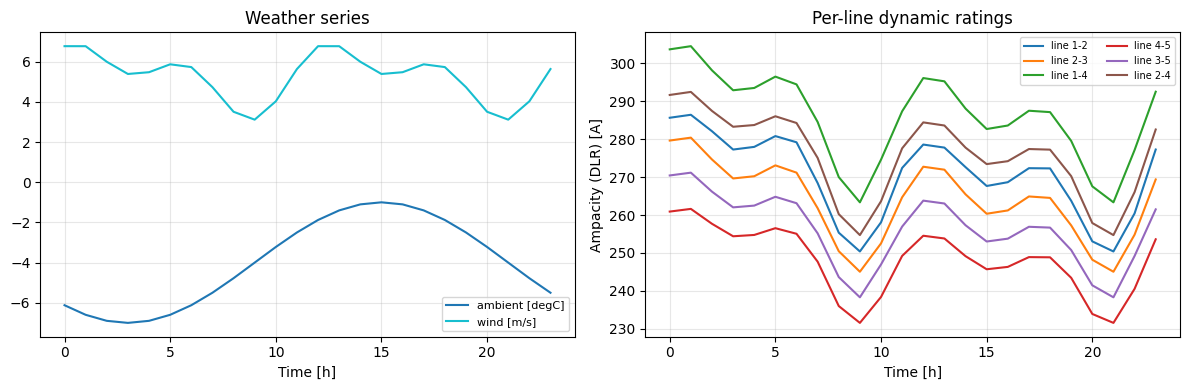

In [10]:
hours_c = np.arange(0, 86400, 3600.0)
t_amb_series = np.array([air_temp_c(t) for t in hours_c])
wind_series = 3.0 + 2.5 * np.sin(2 * np.pi * hours_c / 86400.0 + 1.0) ** 2 + 2.0 * np.cos(2 * np.pi * hours_c / 43200.0) ** 2
amp_series = np.array([[float(AMPACITY_MAP(ta, w * LINES[k][3])) for k in range(len(LINES))]
                       for ta, w in zip(t_amb_series, wind_series)])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(hours_c / 3600, t_amb_series, color="tab:blue", label="ambient [degC]")
axes[0].plot(hours_c / 3600, wind_series, color="tab:cyan", label="wind [m/s]")
axes[0].set_xlabel("Time [h]")
axes[0].legend(fontsize=8)
axes[0].set_title("Weather series")
axes[0].grid(alpha=0.3)
for k, (f_bus, t_bus, _, _) in enumerate(LINES):
    axes[1].plot(hours_c / 3600, amp_series[:, k], label=f"line {f_bus}-{t_bus}")
axes[1].set_xlabel("Time [h]")
axes[1].set_ylabel("Ampacity (DLR) [A]")
axes[1].set_title("Per-line dynamic ratings")
axes[1].legend(fontsize=7, ncol=2)
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [11]:
OCT_RESULT = None
if HAS_OCT:
    try:
        from oct2py import Oct2Py
        oc = Oct2Py()
        oc.addpath(str(WORK_DIR))
        has_mp = oc.exist("runpf")
        print("MATPOWER runpf found on the Octave path." if has_mp else
              "MATPOWER is not installed: nr_powerflow is the only solver here (runpf would be an independent check).")
        branch = build_branch(mva_cold_windy)
        vm_o, va_o, pf_o, qf_o = oc.nr_powerflow(BASE_MVA, BUS, GEN, branch, nout=4)
        vm_py, va_py, sf_py = newton_raphson_pf(BASE_MVA, BUS, GEN, branch)
        dv_oct = float(np.max(np.abs(np.ravel(vm_o) - vm_py)))
        print(f"max |Vm Octave - Vm NumPy| = {dv_oct:.2e} pu")
        OCT_RESULT = dv_oct
        oc.exit()
    except Exception as exc:
        print(f"SKIP Octave solver (Octave not usable: {exc}).")
else:
    print("SKIP Octave solver: oct2py is not installed (the NumPy solver and pandapower check above still ran).")

SKIP Octave solver: oct2py is not installed (the NumPy solver and pandapower check above still ran).


## Where to go next

* **13 - District heat, house archetypes and an electric feeder**: the feeder and heat-network coupling
  that section A and section B build on.
* **16 - FMU with built-in physics**: FMU plants alongside built-in models.
* **02 - Grid co-simulation with pandapower, PyPSA and OpenDSS**: the basic grid solvers in one world.
* **03 - Custom models and parametrization**: writing your own `ModelComponent`, as used for the inverter.